##DIABETES ANALYSIS
To identify which health measurements are most associated with disbetes and to build a model that predicts diabetes status from them.



In [2]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print("Good to go!")

Good to go!


In [3]:
df= pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


DATA: 
The dataset was gotten from Kaggle (https://www.kaggle.com/datasets/mragpavank/diabetes?resource=download)
The Kaggle diabetes dataset contains 768 patients with 8 health measurements( Pregnancies, glucose,blood pressure, skin thickness, insulin, BMI, diabetes pedigree function, age) and a binary outcome (0=no diabetes, 1=diabetes).

In [5]:
#Inspect the data set 
print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
(768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose             

In [6]:
# Outcome distribution
print("\nOutcome couns:")
print(df["Outcome"].value_counts())

print("\nOutcome percentages:")
print(
    (df["Outcome"].value_counts(normalize=True)*100).round(2)
)


Outcome couns:
Outcome
0    500
1    268
Name: count, dtype: int64

Outcome percentages:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


In [7]:
#Compare health indicators by outcome
features=[
    "Glucose", "BMI", "Age", "BloodPressure", "Insulin", "DiabetesPedigreeFunction"
]

print("\nAverage values by outcome:")
print(df.groupby("Outcome")[features].mean().round(2))


Average values by outcome:
         Glucose    BMI    Age  BloodPressure  Insulin  \
Outcome                                                  
0         109.98  30.30  31.19          68.18    68.79   
1         141.26  35.14  37.07          70.82   100.34   

         DiabetesPedigreeFunction  
Outcome                            
0                            0.43  
1                            0.55  


In [8]:
#Check potentially invalid zeros
zero_columns=[
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

print("\nAverage values by outcome:")
print(df.groupby("Outcome")[features].mean(),round(2))


Average values by outcome:
            Glucose        BMI        Age  BloodPressure     Insulin  \
Outcome                                                                
0        109.980000  30.304200  31.190000      68.184000   68.792000   
1        141.257463  35.142537  37.067164      70.824627  100.335821   

         DiabetesPedigreeFunction  
Outcome                            
0                        0.429734  
1                        0.550500   2


DATA CLEANING
It was noticed during visualization that Glucose, BloodPressure, SkinThickness,Insulin and BMI contained zeros which are impossible, These were treated as missing values and was relaced with each column's median. the box plots confirmed the fix: the impossible zero outliers disappeared.


Text(0.5, 0, 'Outcome:0=Negative,1=Positive')

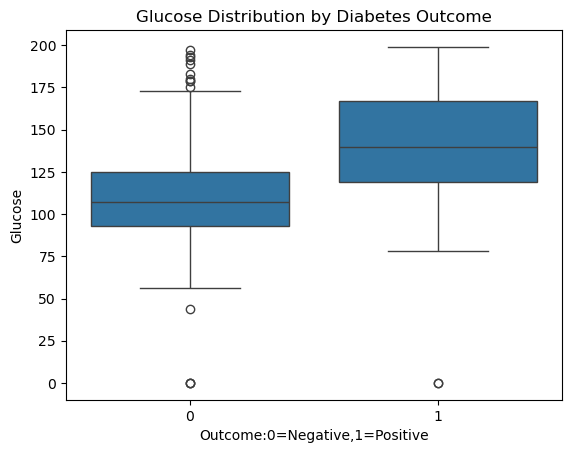

In [10]:
#Visualize glucose by outcome
sns.boxplot(data=df,x="Outcome",y="Glucose")
plt.title("Glucose Distribution by Diabetes Outcome")
plt.xlabel("Outcome:0=Negative,1=Positive")

In [11]:
#The circles at zero are a data problem. A glucose of 0 is impossible, so we are going to replace the missing values written as zero for glucose with the median
df["Glucose"]=df["Glucose"].replace(0,df["Glucose"].median())

Text(0.5, 0, 'Outcome:0=Negative,1=Positive')

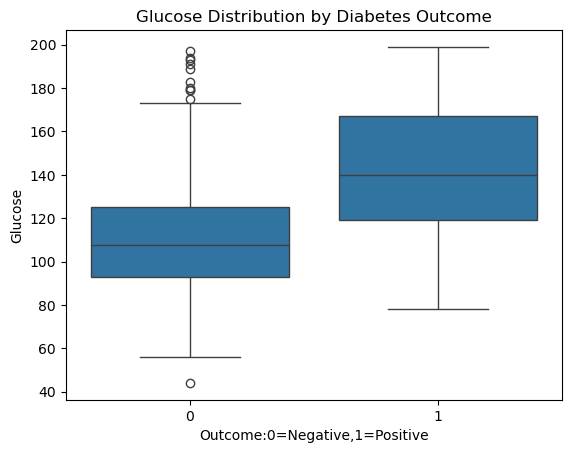

In [12]:
sns.boxplot(data=df,x="Outcome",y="Glucose")
plt.title("Glucose Distribution by Diabetes Outcome")
plt.xlabel("Outcome:0=Negative,1=Positive")

Text(0.5, 0, 'Outcome:0=Negative,1=Positive')

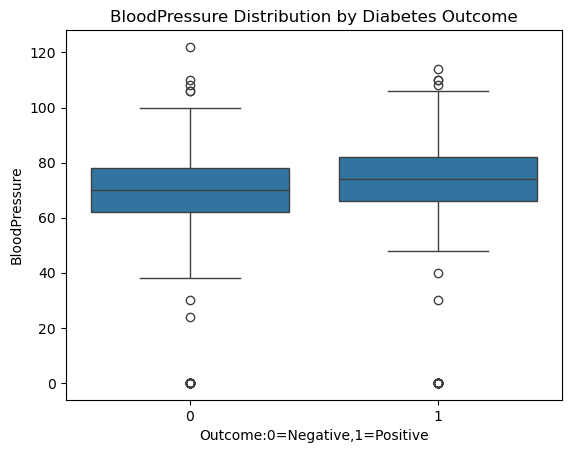

In [13]:
#Repeat the same zero check on other columns where 0 is impossible
sns.boxplot(data=df,x="Outcome",y="BloodPressure")
plt.title("BloodPressure Distribution by Diabetes Outcome")
plt.xlabel("Outcome:0=Negative,1=Positive")

In [14]:
df["BloodPressure"]=df["BloodPressure"].replace(0,df["BloodPressure"].median())

Text(0.5, 0, 'Outcome:0=Negative,1=Positive')

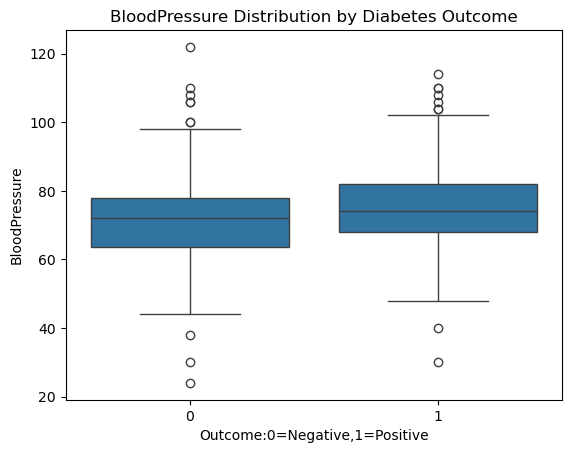

In [15]:
sns.boxplot(data=df,x="Outcome",y="BloodPressure")
plt.title("BloodPressure Distribution by Diabetes Outcome")
plt.xlabel("Outcome:0=Negative,1=Positive")

Text(0.5, 0, 'Outcome:0=Negative,1=Positive')

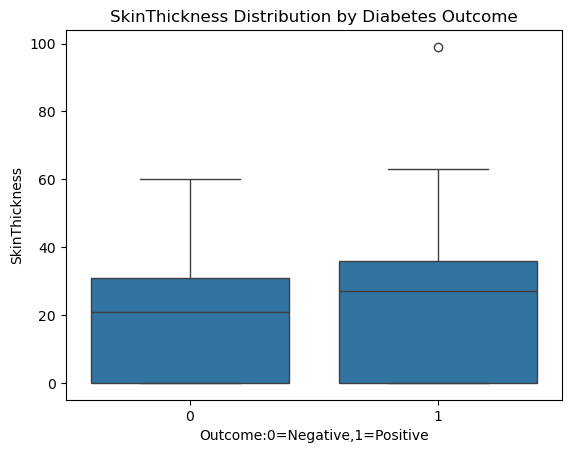

In [16]:
sns.boxplot(data=df,x="Outcome",y="SkinThickness")
plt.title("SkinThickness Distribution by Diabetes Outcome")
plt.xlabel("Outcome:0=Negative,1=Positive")

In [17]:
df["SkinThickness"]=df["SkinThickness"].replace(0,df["SkinThickness"].median())

Text(0.5, 0, 'Outcome:0=Negative,1=Positive')

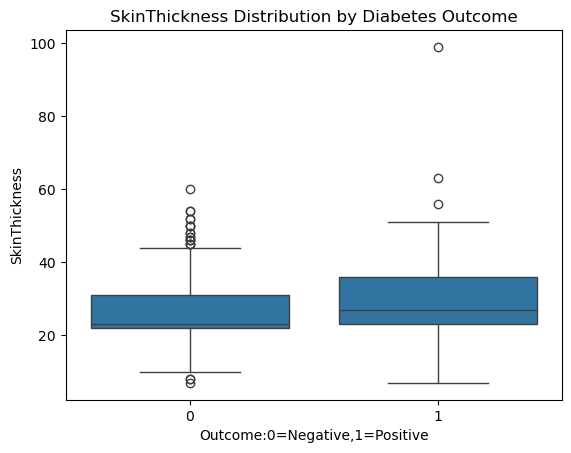

In [18]:
sns.boxplot(data=df,x="Outcome",y="SkinThickness")
plt.title("SkinThickness Distribution by Diabetes Outcome")
plt.xlabel("Outcome:0=Negative,1=Positive")

In [19]:
df["SkinThickness"]= df["SkinThickness"].replace(0,pd.NA)
df["SkinThickness"]= df["SkinThickness"].fillna(df.groupby("Outcome")["SkinThickness"].transform("median"))

Text(0.5, 0, 'Outcome:0=Negative,1=Positive')

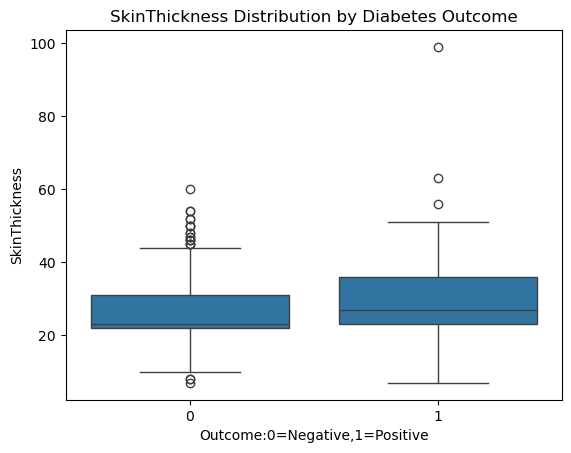

In [20]:
sns.boxplot(data=df,x="Outcome",y="SkinThickness")
plt.title("SkinThickness Distribution by Diabetes Outcome")
plt.xlabel("Outcome:0=Negative,1=Positive")

Text(0.5, 0, 'Outcome:0=Negative,1=Positive')

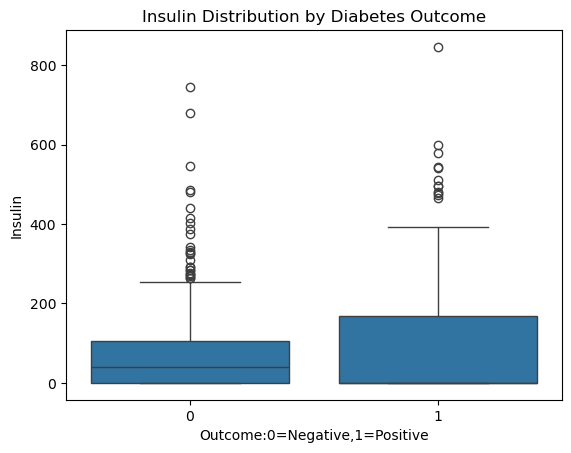

In [21]:
sns.boxplot(data=df,x="Outcome",y="Insulin")
plt.title("Insulin Distribution by Diabetes Outcome")
plt.xlabel("Outcome:0=Negative,1=Positive")


In [22]:
df["Insulin"]= df["Insulin"].replace(0,df["Insulin"].median())

Text(0.5, 0, 'Outcome:0=Negative,1=Positive')

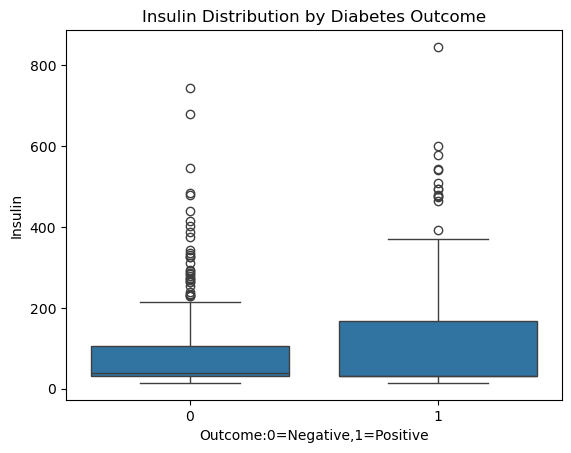

In [23]:
sns.boxplot(data=df,x="Outcome",y="Insulin")
plt.title("Insulin Distribution by Diabetes Outcome")
plt.xlabel("Outcome:0=Negative,1=Positive")

Text(0.5, 0, 'Outcome:0=Negative,1=Positive')

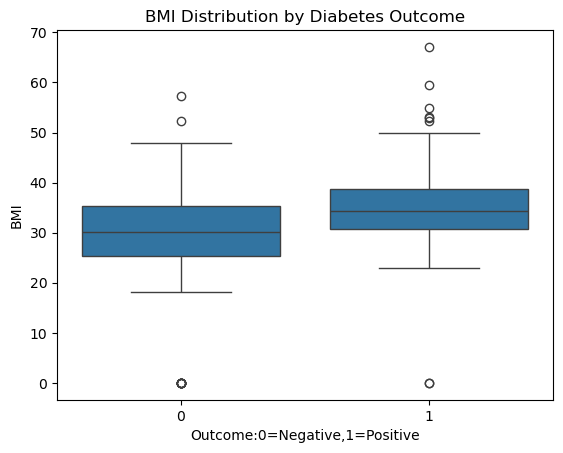

In [24]:
sns.boxplot(data=df,x="Outcome",y="BMI")
plt.title("BMI Distribution by Diabetes Outcome")
plt.xlabel("Outcome:0=Negative,1=Positive")

In [25]:
df["BMI"]= df["BMI"].replace(0, df["BMI"].median())

Text(0.5, 0, 'Outcome:0=Negative,1=Positive')

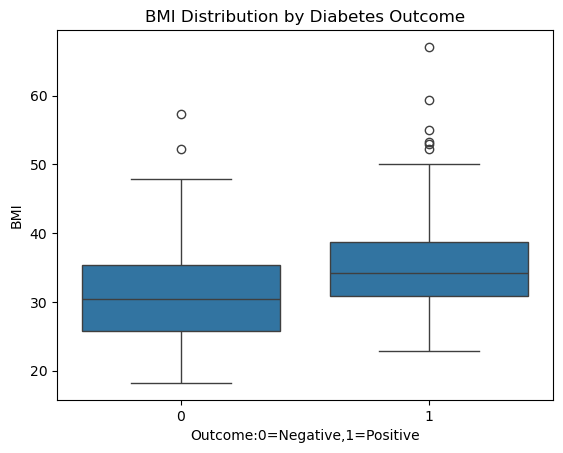

In [26]:
sns.boxplot(data=df,x="Outcome",y="BMI")
plt.title("BMI Distribution by Diabetes Outcome")
plt.xlabel("Outcome:0=Negative,1=Positive")

EXPLORATORY ANALYSIS
Box plots compared each measurement between patients with and without diabetes.
Glucose (0.49) seperated the groups clearly,followed by BMI(0.31), BloodPressure(0.17) barely differed between groups , Skinthickness(0.19) and Insulin(0.15) showed moderate to small differences.

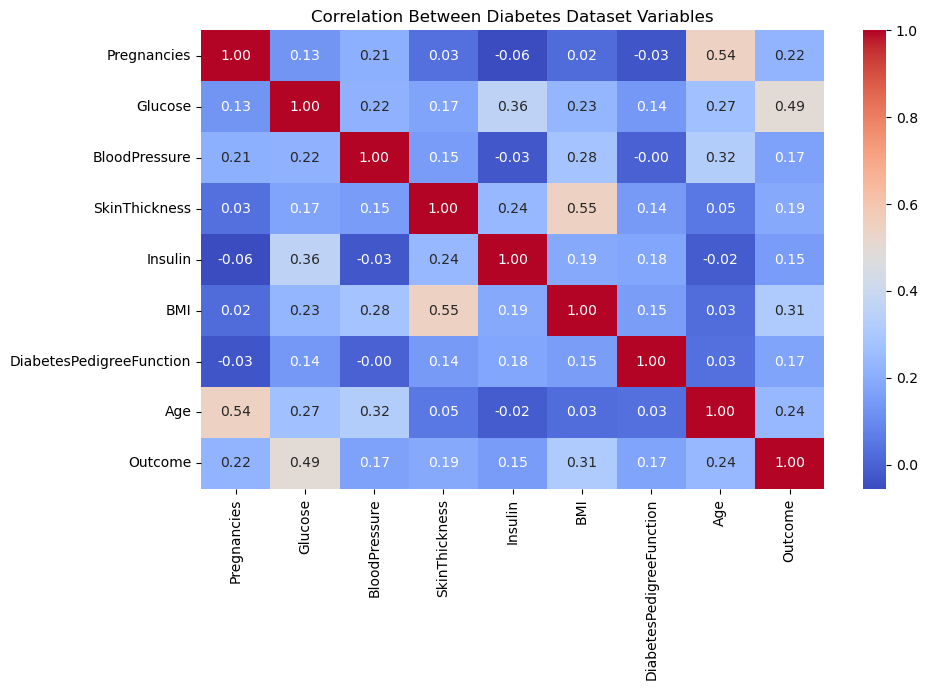

In [28]:
#Correlation analysis
plt.figure(figsize=(10,7))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Diabetes Dataset Variables")
plt.tight_layout()
plt.show()

In [29]:
#Building a Model (Logistic Regression)
#Split the data into training, validation and the testing.
from sklearn.model_selection import train_test_split

X = df.drop("Outcome", axis=1)
Y = df["Outcome"]

# 70% Train, 30% temporary

X_train, X_temp, Y_train,Y_temp = train_test_split(X, Y, test_size=0.30,random_state=42,stratify=Y)

#Split the 30% into 15% validation and 15% test
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp,test_size=0.50,random_state=42, stratify=Y_temp)

print(len(X_train), len(X_val), len(X_test))

537 115 116


In [30]:
#Scale the features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [31]:
#Train the model
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train,Y_train)

LogisticRegression()

In [32]:
from sklearn.metrics import accuracy_score, classification_report
val_pred = model.predict(X_val)
print("Validation accuracy:", accuracy_score(Y_val, val_pred))
print (classification_report(Y_val, val_pred))

Validation accuracy: 0.7217391304347827
              precision    recall  f1-score   support

           0       0.77      0.81      0.79        75
           1       0.61      0.55      0.58        40

    accuracy                           0.72       115
   macro avg       0.69      0.68      0.69       115
weighted avg       0.72      0.72      0.72       115



In [33]:
# Class 1 Precision (0.61) and recall (0.55), this model does better on non-diabetic people because there are more of them , so this leans toward predicting no diabetes.
#To improve this model, we will have to balance the classes

model= LogisticRegression(class_weight="balanced")
model.fit(X_train, Y_train)
val_pred = model.predict(X_val)
print(classification_report(Y_val, val_pred))


              precision    recall  f1-score   support

           0       0.85      0.73      0.79        75
           1       0.60      0.75      0.67        40

    accuracy                           0.74       115
   macro avg       0.72      0.74      0.73       115
weighted avg       0.76      0.74      0.74       115



In [34]:
from sklearn.metrics import accuracy_score, classification_report

test_pred = model.predict(X_test)
print("Test accuracy:", accuracy_score(Y_test, test_pred))
print(classification_report(Y_test,test_pred))

Test accuracy: 0.7672413793103449
              precision    recall  f1-score   support

           0       0.82      0.83      0.82        75
           1       0.68      0.66      0.67        41

    accuracy                           0.77       116
   macro avg       0.75      0.74      0.74       116
weighted avg       0.77      0.77      0.77       116



MODELING
The data was split 70% training (537), 15% validation (115) and 15% testing (116), stratified to keep the diabetes ratio equal. Features were standardized using statistics from the training set only.

Balancing the class weights raised recall for diabetes from 0.55 to 0.75. Random Forest had slightly higher accuracy but missed more real cases, so balanced Logistic Regression was chosen.


KEY FINDINGS
On the untouched test set, the chosen model achieved:

Accuracy: 76.7%
Diabetes precision: 0.68 (when it predicts diabetes, it is right 68% of the time)
Diabetes recall: 0.66 (it finds about two thirds of real cases)
Test performance was consistent with validation, so the model does not appear to be overfitting.

Conclusions
Glucose is the strongest single indicator of diabetes in this dataset, followed by BMI.
Cleaning impossible zero values was essential before analysis.
Handling class imbalance had a larger effect on catching real cases than changing model type.
A simple, interpretable model reached about 77% accuracy.

